# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import CaBuArDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import numpy as np
import h5py

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/CaBuAr/burned_512x512.hdf5"
}
dataset = CaBuArDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 727


# Show images

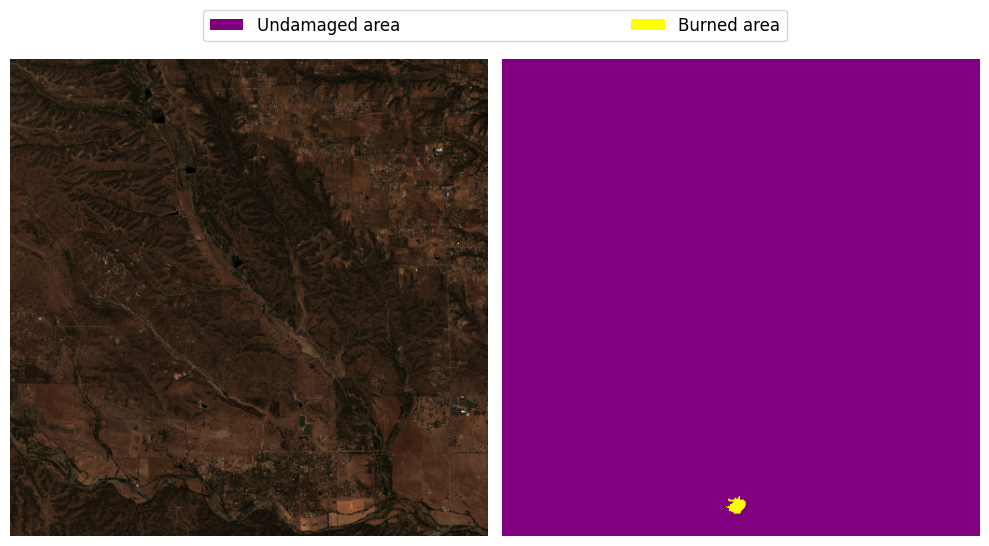

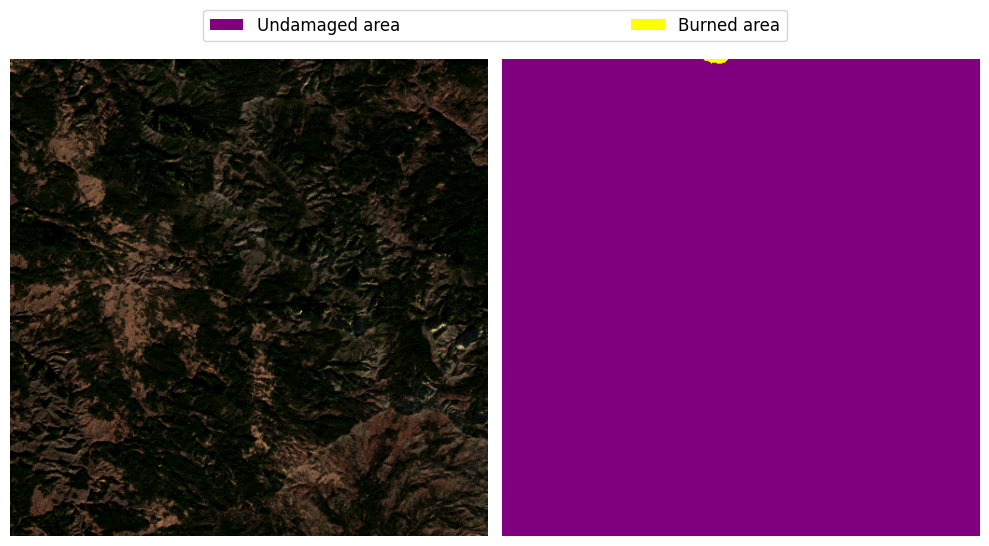

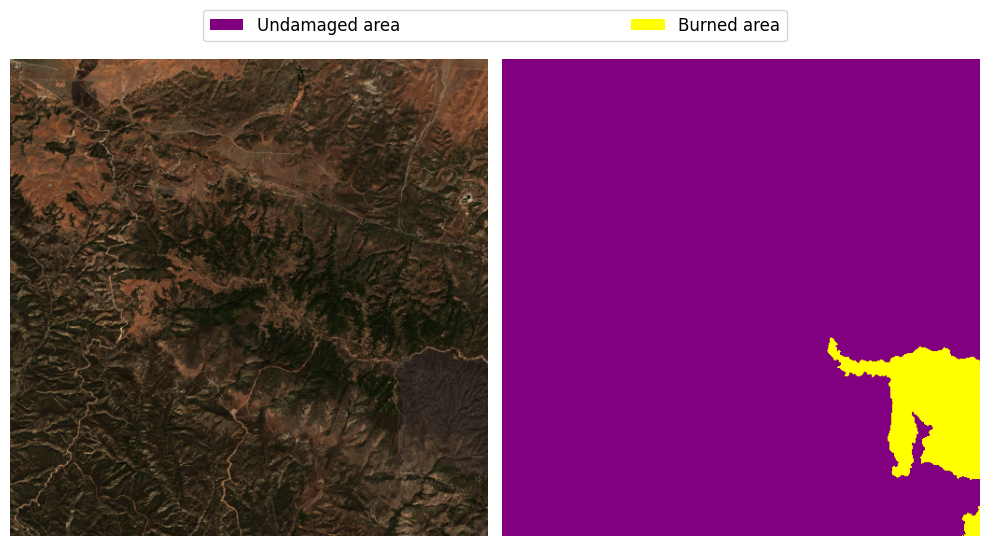

In [35]:
dataset.show_image(10)
dataset.show_image(100)
dataset.show_image(300);

In [6]:
dataset.data_distribution_table()

,Label,Number of pixels
0,Undamaged area,162457775
1,Burned area,28120913


2025-09-01 10:14:33,776 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-01 10:14:33,782 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


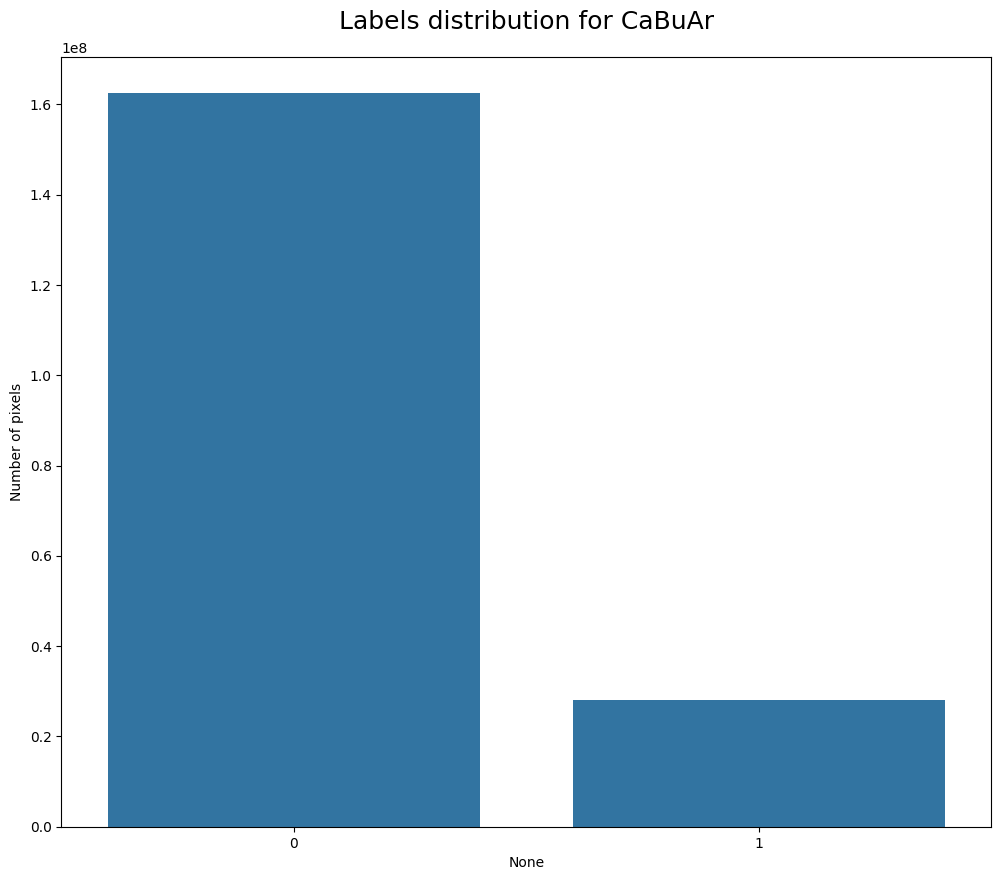

In [7]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/CaBuAr/burned_512x512.hdf5",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = CaBuArDataset(train_dataset_config)

len(train_dataset)

582

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/CaBuAr"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [50]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-07-28 08:00:14,778 INFO Starting training.
training: 100%|██████████| 146/146 [00:15<00:00,  9.62it/s]
2025-07-28 08:00:30,679 INFO epoch: 1, time: 15, loss:  0.39837
testing on train set: 100%|██████████| 146/146 [00:05<00:00, 26.22it/s]
2025-07-28 08:00:37,895 INFO IOU:0.6245042029061091, IOU mean:0.42566666519993585, IOU per Class:[0.77233823 0.0789951 ]
training: 100%|██████████| 146/146 [00:14<00:00,  9.99it/s]
2025-07-28 08:00:52,517 INFO epoch: 2, time: 15, loss:  0.30905
testing on train set: 100%|██████████| 146/146 [00:05<00:00, 27.02it/s]
2025-07-28 08:00:57,930 INFO IOU:0.65222885457736, IOU mean:0.44753838646423055, IOU per Class:[0.81063065 0.08444612]
training: 100%|██████████| 146/146 [00:14<00:00,  9.98it/s]
2025-07-28 08:01:12,561 INFO epoch: 3, time: 15, loss:  0.25278
testing on train set: 100%|██████████| 146/146 [00:05<00:00, 26.47it/s]
2025-07-28 08:01:18,088 INFO IOU:0.7104841390402022, IOU mean:0.40919630945226343, IOU per Class:[0.81839262 0.        ]
tra

0.1608045639860671

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "./data/CaBuAr/burned_512x512.hdf5",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = CaBuArDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/CaBuAr/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

73


2025-07-28 08:04:22,721 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/CaBuAr/checkpoint.pth.tar
2025-07-28 08:04:24,586 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/CaBuAr/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 19/19 [00:01<00:00, 16.07it/s]


[{'IOU': 0.8137527249793546,
  'IOU mean': 0.4471640390892551,
  'IOU per Class': array([0.89432808, 0.        ])}]

## Predictions

2025-07-28 08:08:31,713 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/CaBuAr/checkpoint.pth.tar
2025-07-28 08:08:33,141 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/CaBuAr/checkpoint.pth.tar at epoch 11


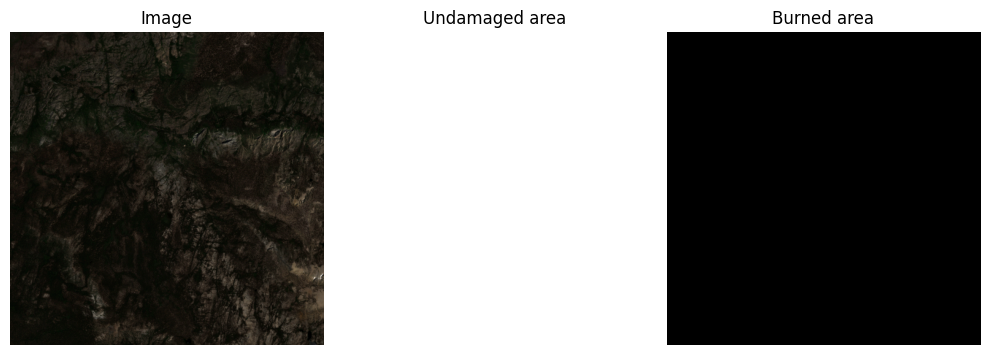

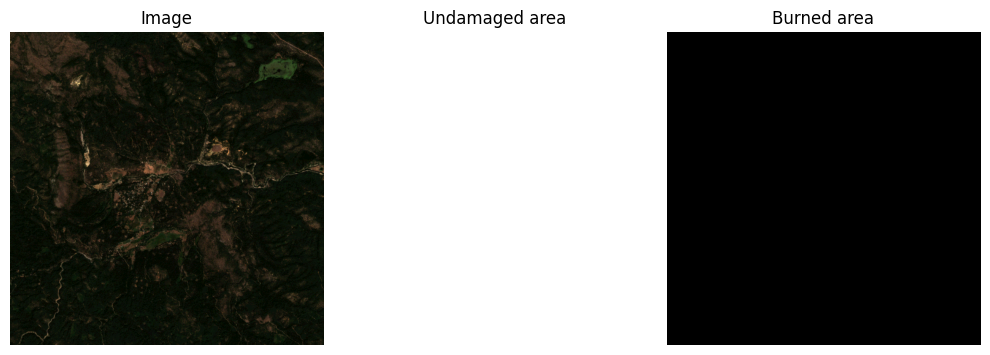

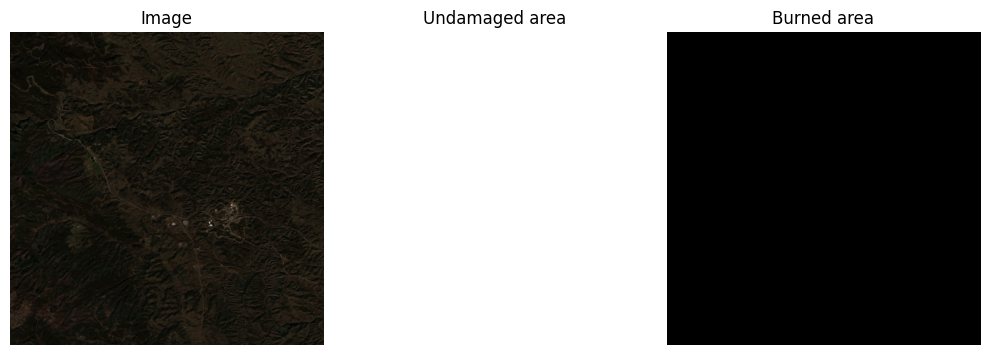

In [ ]:
model_path = "./data/experiments/CaBuAr/checkpoint.pth.tar"
data_dir = "./data/CaBuAr/burned_512x512.hdf5"
mode = 'test'
labels = ["Undamaged area","Burned area"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

for i in np.arange(3):
    with h5py.File(data_dir, 'r') as h5_file:
        data = list(h5_file.keys())
        if mode == 'test':
            data = data[655 :]
        key = data[i]
        integer_mask = h5_file[key]["mask"][:]
        image = h5_file[key]["post_fire"][:,:,[1,2,3]]
        image = image[:,:,[2,1,0]]

        image = image.astype(np.float32)
        if image.max() > 1.0:
            image = (image - image.min()) / (image.max() - image.min())
            
        fig = model.predict_masks(image, labels, transform)